# Attachment A: NextStar Recommender System Experiments
**Akshu Karki**, MSAI-511-A02

This notebook is the "show your work" part of my NextStar case study paper. NextStar doesn't exist yet, so there's no real NextStar data. Instead I used the **MovieLens 100K** dataset (Harper & Konstan, 2015), which has 100,000 ratings (1–5 stars) from 943 users on 1,682 movies. It's basically the same kind of user–item rating matrix NextStar would have, just with movies instead of clips from new artists.

What I do here:
1. Work through the small error example from the case study by hand
2. Build a matrix factorization recommender trained with stochastic gradient descent (SGD), using an 80/20 train/test split and RMSE/MAE
3. Show overfitting by training with and without regularization
4. Measure precision, recall, and the F-measure of the top-10 recommendations
5. Measure popularity bias, then try a simple re-ranking fix

In [1]:
import os, urllib.request, zipfile
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

## 1. The case study's error example
In the case study, user US1 gave item IT1 a rating of 3, and the matrix factorization predicted 2.18. The squared error for that cell is:

In [2]:
actual, predicted = 3, 2.18
print("error =", actual - predicted)
print("squared error =", round((actual - predicted) ** 2, 4))

error = 0.8199999999999998
squared error = 0.6724


This matches the 0.6724 in the case study. SGD looks at errors like this for every known rating and nudges the user and item feature values a little bit each time to make the error smaller.

## 2. Load the data and split 80/20
The dataset's license doesn't allow sharing it, so the cell downloads it from GroupLens if it isn't already there.

In [3]:
if not os.path.exists("ml-100k/u.data"):
    urllib.request.urlretrieve(
        "https://files.grouplens.org/datasets/movielens/ml-100k.zip",
        "ml-100k.zip",
    )
    zipfile.ZipFile("ml-100k.zip").extractall(".")

data = np.loadtxt("ml-100k/u.data", dtype=int)[:, :3]
data[:, 0] -= 1  # make user and item ids start at 0
data[:, 1] -= 1
n_users, n_items = data[:, 0].max() + 1, data[:, 1].max() + 1
print(f"{len(data)} ratings, {n_users} users, {n_items} items")
print(
    f"matrix is {len(data) / (n_users * n_items):.1%} filled (very sparse)"
)

idx = rng.permutation(len(data))
cut = int(0.8 * len(data))
train, test = data[idx[:cut]], data[idx[cut:]]
print(f"train: {len(train)}  test: {len(test)}")

100000 ratings, 943 users, 1682 items
matrix is 6.3% filled (very sparse)
train: 80000  test: 20000


## 3. Matrix factorization with SGD
Each user and each item gets a vector of `k` hidden features. The predicted rating is the overall average, plus a user bias, plus an item bias, plus the dot product of the two feature vectors (Koren et al., 2009). For every rating in the training set, SGD computes the error and moves the values a small step in the direction that lowers it.

`reg` is the regularization strength. It adds a penalty to the cost function when the feature values get big, which is one of the anti-overfitting strategies from my paper.

In [4]:
def rmse_mae(P, Q, bu, bi, mu, ratings):
    u, i, r = ratings[:, 0], ratings[:, 1], ratings[:, 2]
    pred = np.clip(
        mu + bu[u] + bi[i] + np.sum(P[u] * Q[i], axis=1), 1, 5
    )
    err = r - pred
    return np.sqrt(np.mean(err**2)), np.mean(np.abs(err))


def train_mf(train, test, k=50, lr=0.01, reg=0.05, epochs=40, seed=0):
    r = np.random.default_rng(seed)
    P = r.normal(0, 0.1, (n_users, k))
    Q = r.normal(0, 0.1, (n_items, k))
    bu, bi = np.zeros(n_users), np.zeros(n_items)
    mu = train[:, 2].mean()
    history = []
    for epoch in range(epochs):
        for u, i, rating in train[r.permutation(len(train))]:
            err = rating - (mu + bu[u] + bi[i] + P[u] @ Q[i])
            bu[u] += lr * (err - reg * bu[u])
            bi[i] += lr * (err - reg * bi[i])
            P[u], Q[i] = (
                P[u] + lr * (err * Q[i] - reg * P[u]),
                Q[i] + lr * (err * P[u] - reg * Q[i]),
            )
        history.append(
            (
                rmse_mae(P, Q, bu, bi, mu, train)[0],
                rmse_mae(P, Q, bu, bi, mu, test)[0],
            )
        )
    return (P, Q, bu, bi, mu), np.array(history)

For comparison, a really simple baseline that just predicts the average rating for everything:

In [5]:
mu = train[:, 2].mean()
base_rmse = np.sqrt(np.mean((test[:, 2] - mu) ** 2))
base_mae = np.mean(np.abs(test[:, 2] - mu))
print(f"baseline (always predict {mu:.2f}):")
print(f"RMSE = {base_rmse:.4f}, MAE = {base_mae:.4f}")

baseline (always predict 3.53):
RMSE = 1.1331, MAE = 0.9507


## 4. Overfitting: with vs. without regularization
I train the same model twice for 40 epochs. The only difference is `reg = 0` (no regularization) vs `reg = 0.05`.

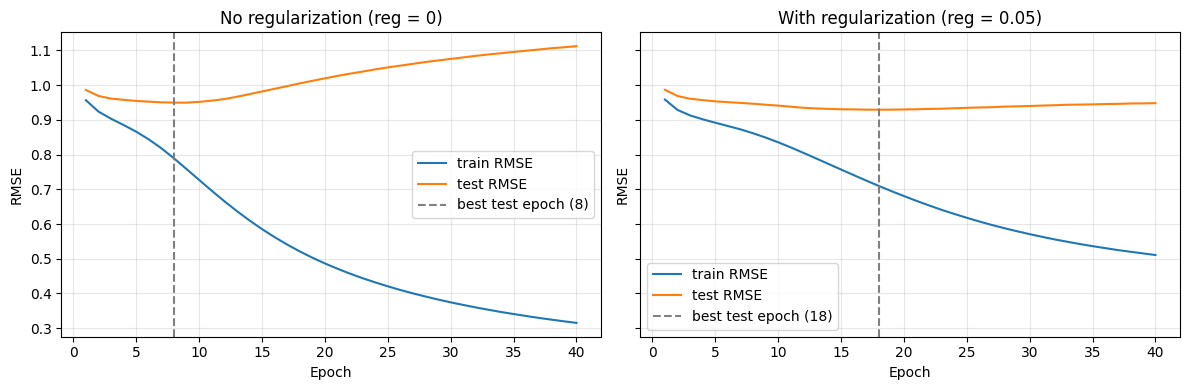

no reg: final train RMSE 0.3154
no reg: final test RMSE  1.1119
no reg: best test RMSE   0.9494 (epoch 8)
reg 0.05: final train RMSE 0.5107
reg 0.05: final test RMSE  0.9478
reg 0.05: best test RMSE   0.9291 (epoch 18)


In [6]:
model_noreg, hist_noreg = train_mf(train, test, reg=0.0)
model_reg, hist_reg = train_mf(train, test, reg=0.05)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, hist, title in [
    (axes[0], hist_noreg, "No regularization (reg = 0)"),
    (axes[1], hist_reg, "With regularization (reg = 0.05)"),
]:
    ax.plot(range(1, 41), hist[:, 0], label="train RMSE")
    ax.plot(range(1, 41), hist[:, 1], label="test RMSE")
    best = hist[:, 1].argmin()
    ax.axvline(
        best + 1,
        color="gray",
        ls="--",
        label=f"best test epoch ({best + 1})",
    )
    ax.set(title=title, xlabel="Epoch", ylabel="RMSE")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("overfitting.png", dpi=120)
plt.show()

for name, h in [("no reg", hist_noreg), ("reg 0.05", hist_reg)]:
    b = h[:, 1].argmin()
    print(f"{name}: final train RMSE {h[-1, 0]:.4f}")
    print(f"{name}: final test RMSE  {h[-1, 1]:.4f}")
    print(f"{name}: best test RMSE   {h[b, 1]:.4f} (epoch {b + 1})")

In [7]:
P, Q, bu, bi, mu = model_reg
rmse, mae = rmse_mae(P, Q, bu, bi, mu, test)
print(
    f"regularized model on the test set: RMSE = {rmse:.4f}, MAE = {mae:.4f}"
)
print(
    f"improvement over baseline RMSE: {(base_rmse - rmse) / base_rmse:.1%}"
)

regularized model on the test set: RMSE = 0.9478, MAE = 0.7432
improvement over baseline RMSE: 16.4%


## 5. Top-10 recommendations: precision, recall, F-measure
For each user, I score every item they haven't rated in the training set and take the top 10. An item counts as "relevant" if the user rated it 4 or 5 in the test set.

These numbers look low, and that's normal for offline testing. The test set only knows about items the user happened to rate, so a good recommendation the user never saw counts as a miss. This is why the case study says the real effectiveness is only known once real users try it.

In [8]:
train_pop = np.bincount(train[:, 1], minlength=n_items)
rated = [set() for _ in range(n_users)]
for u, i, _ in train:
    rated[u].add(i)
relevant = [set() for _ in range(n_users)]
for u, i, r in test:
    if r >= 4:
        relevant[u].add(i)

# predicted score for every user/item pair
scores = mu + bu[:, None] + bi[None, :] + np.einsum("uk,ik->ui", P, Q)
head = set(
    np.argsort(-train_pop)[: n_items // 10]
)  # top 10% most rated items


def evaluate(scores, n=10):
    precs, recs, all_recs = [], [], []
    for u in range(n_users):
        s = scores[u].copy()
        s[list(rated[u])] = -np.inf
        top = np.argsort(-s)[:n]
        all_recs.extend(top)
        if relevant[u]:
            hits = len(set(top) & relevant[u])
            precs.append(hits / n)
            recs.append(hits / len(relevant[u]))
    p, r = np.mean(precs), np.mean(recs)
    return {
        "precision@10": p,
        "recall@10": r,
        "F-measure": 2 * p * r / (p + r),
        "coverage": len(set(all_recs)) / n_items,
        "% from top 10%": np.mean([i in head for i in all_recs]),
        "avg # ratings": train_pop[all_recs].mean(),
    }


plain = evaluate(scores)
for key, v in plain.items():
    print(f"{key:>15}: {v:.3f}" if v < 10 else f"{key:>15}: {v:.1f}")

   precision@10: 0.060
      recall@10: 0.048
      F-measure: 0.054
       coverage: 0.289
 % from top 10%: 0.388
  avg # ratings: 120.9


## 6. Popularity bias, and a re-ranking fix
The last three numbers above show the popularity bias. **Coverage** is the share of all items that get recommended to anybody. **% from top 10%** is how many recommendations come from the 10% most-rated items. The average item in the catalog only has this many ratings:

In [9]:
print(
    f"average ratings per item in the catalog: {train_pop.mean():.1f}"
)
few = (train_pop < 10).mean()
print(f"items with fewer than 10 ratings: {few:.1%}")

average ratings per item in the catalog: 47.6
items with fewer than 10 ratings: 35.5%


To fix this, I subtract a popularity penalty from each score before picking the top 10: `new score = score - λ × log(1 + number of ratings)`. A bigger λ pushes harder toward less popular items. This is a simple version of the re-ranking idea from Abdollahpouri et al. (2017).

λ=0.0  prec=0.060 F=0.054 cov=28.9% top10%=38.8% avg_ratings=121


λ=0.05 prec=0.045 F=0.040 cov=29.8% top10%=26.3% avg_ratings=90
λ=0.1  prec=0.026 F=0.023 cov=30.1% top10%=13.6% avg_ratings=55


λ=0.2  prec=0.006 F=0.004 cov=24.8% top10%=1.8% avg_ratings=13


λ=0.3  prec=0.002 F=0.001 cov=15.2% top10%=0.2% avg_ratings=4


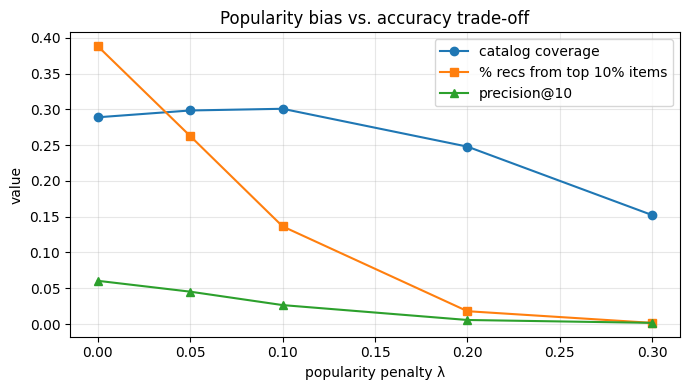

In [10]:
log_pop = np.log1p(train_pop)
rows = []
for lam in [0.0, 0.05, 0.1, 0.2, 0.3]:
    res = evaluate(scores - lam * log_pop[None, :])
    rows.append((lam, res))
    print(
        f"λ={lam:<4} prec={res['precision@10']:.3f}",
        f"F={res['F-measure']:.3f}",
        f"cov={res['coverage']:.1%}",
        f"top10%={res['% from top 10%']:.1%}",
        f"avg_ratings={res['avg # ratings']:.0f}",
    )

lams = [r[0] for r in rows]
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.plot(
    lams,
    [r[1]["coverage"] for r in rows],
    "o-",
    label="catalog coverage",
)
ax1.plot(
    lams,
    [r[1]["% from top 10%"] for r in rows],
    "s-",
    label="% recs from top 10% items",
)
ax1.plot(
    lams,
    [r[1]["precision@10"] for r in rows],
    "^-",
    label="precision@10",
)
ax1.set(
    xlabel="popularity penalty λ",
    ylabel="value",
    title="Popularity bias vs. accuracy trade-off",
)
ax1.legend()
ax1.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("popularity_bias.png", dpi=120)
plt.show()

## 7. What I took from this
- **Overfitting:** without regularization, training RMSE keeps dropping (down to 0.32) but test RMSE bottoms out at epoch 8 and then climbs back to 1.11, which is almost as bad as just guessing the average (1.13). That's textbook overfitting. With regularization (reg = 0.05) the final test RMSE is 0.948 and MAE is 0.743, about 16% better than the baseline. Early stopping at the best epoch would help a bit more (0.929).
- **Popularity bias:** the plain model takes 38.8% of its recommendations from the 10% most-rated items, which is almost 4 times their 10% share of the catalog. The average recommended item has 121 ratings, while the average item in the catalog has only about 48.
- **Re-ranking:** a small penalty (λ = 0.1) cuts the share of top-10% items from 38.8% to 13.6% and the average popularity from 121 to 55 ratings. But it does **not** really increase coverage (28.9% → 30.1%), and precision drops from 0.060 to 0.026. If the penalty is too big (λ = 0.3), it just swaps one bias for another: everyone gets the same few obscure items with about 4 ratings each, and coverage falls to 15%.
- Part of the precision drop is probably the offline test itself. People are more likely to have rated popular items, so the test set rewards recommending them. This is why NextStar would need to test with real users (for example, A/B tests) and not only offline scores.

For NextStar, I think this shows that fixing popularity bias needs a careful balance. A small penalty or a guaranteed share of new artists in each list makes sense, but pushing too hard just recommends random unknown content that people won't like.

### References
Abdollahpouri, H., Burke, R., & Mobasher, B. (2017). Controlling popularity bias in learning-to-rank recommendation. In *Proceedings of the Eleventh ACM Conference on Recommender Systems* (pp. 42–46). https://doi.org/10.1145/3109859.3109912

Harper, F. M., & Konstan, J. A. (2015). The MovieLens datasets: History and context. *ACM Transactions on Interactive Intelligent Systems, 5*(4), Article 19. https://doi.org/10.1145/2827872

Koren, Y., Bell, R., & Volinsky, C. (2009). Matrix factorization techniques for recommender systems. *Computer, 42*(8), 30–37. https://doi.org/10.1109/MC.2009.263